# Day 104 — Pure PyTorch MLP Complete Pipeline

**Phase 6: Deep Learning & PyTorch**

## 📌 Topics & Learning Objectives
- End-to-end multi-class classification pipeline
- Custom Dataset & DataLoader with train/test splits
- Multi-layer Perceptron (MLP) with Dropout and ReLU
- Complete training & validation epochs with loss tracking
- Evaluating final classification metrics (Confusion Matrix, Precision/Recall)


### 💡 Concept Overview
This notebook unifies Tensors, Autograd, Dataset, DataLoader, `nn.Module`, Dropout Regularization, CrossEntropyLoss, and Adam optimizer into one production-ready script.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.datasets import make_classification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Multi-Class Dataset (3 Classes, 15 Features)
X, y = make_classification(n_samples=600, n_features=15, n_classes=3, n_informative=10, random_state=42)
full_ds = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
train_ds, test_ds = random_split(full_ds, [480, 120])
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

class CompleteMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(15, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 3)
        )
    def forward(self, x): return self.net(x)

model = CompleteMLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.005, weight_decay=1e-2)

for epoch in range(6):
    model.train()
    for x_b, y_b in train_loader:
        x_b, y_b = x_b.to(device), y_b.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(x_b), y_b)
        loss.backward()
        optimizer.step()
    print(f"Epoch {epoch+1} finished. Loss: {loss.item():.4f}")


Epoch 1 finished. Loss: 0.9917
Epoch 2 finished. Loss: 0.8151
Epoch 3 finished. Loss: 0.8412
Epoch 4 finished. Loss: 0.5927
Epoch 5 finished. Loss: 0.6029
Epoch 6 finished. Loss: 0.4848


Test Accuracy: 70.83%

Classification Report:
               precision    recall  f1-score   support

           0       0.65      0.50      0.56        40
           1       0.76      0.83      0.79        41
           2       0.70      0.79      0.75        39

    accuracy                           0.71       120
   macro avg       0.70      0.71      0.70       120
weighted avg       0.70      0.71      0.70       120



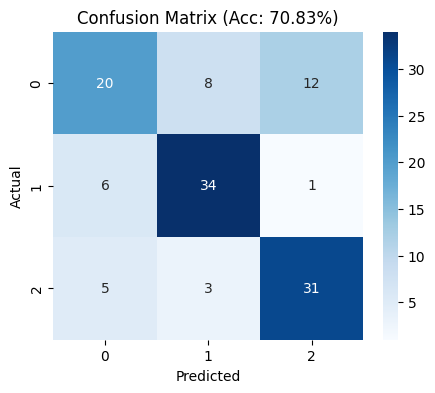

In [2]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for x_b, y_b in test_loader:
        x_b = x_b.to(device)
        preds = model(x_b).argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(y_b.numpy())

acc = accuracy_score(all_labels, all_preds) * 100
cm = confusion_matrix(all_labels, all_preds)

print(f"Test Accuracy: {acc:.2f}%\n")
print("Classification Report:\n", classification_report(all_labels, all_preds))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix (Acc: {acc:.2f}%)")
plt.show()